In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


*Library and	What it does*
1. Pandas-	Organizes and analyzes data
2. NumPy-	Performs numerical operations
3. Matplotlib-	Creates charts
4. Seaborn-	Creates statistical visualizations

In [8]:
np.random.seed(42)

# 1. Define Nairobi matatu routes
routes = {
    "CBD-Rongai": {"distance": 18, "fare": 100, "duration": 50},
    "CBD-Thika": {"distance": 35, "fare": 120, "duration": 65},
    "CBD-Ruiru": {"distance": 28, "fare": 100, "duration": 55},
    "CBD-Ngong": {"distance": 25, "fare": 100, "duration": 60},
    "CBD-Kikuyu": {"distance": 22, "fare": 100, "duration": 50},
    "CBD-Githurai": {"distance": 15, "fare": 80, "duration": 45}
}

# 2. Define departure hours and probabilities
hours = np.array([
    6, 7, 8, 9, 10, 11, 12, 13, 14, 15,
    16, 17, 18, 19, 20
])

probabilities = np.array([
    0.08, 0.12, 0.12, 0.06, 0.04,
    0.04, 0.04, 0.04, 0.04, 0.05,
    0.08, 0.10, 0.09, 0.04, 0.06
])

# Normalize probabilities so they sum to exactly 1
probabilities = probabilities / probabilities.sum()

# 3. Generate 300 simulated trips
records = []

for i in range(300):

    route = np.random.choice(list(routes.keys()))
    details = routes[route]

    hour = np.random.choice(hours, p=probabilities)

    passengers = np.random.randint(5, 15)

    peak = hour in [7, 8, 17, 18]

    fare = details["fare"] + (
        np.random.randint(10, 31) if peak else 0
    )

    scheduled = details["duration"]

    traffic_delay = np.random.randint(0, 36)

    if peak:
        traffic_delay += np.random.randint(5, 21)

    actual = scheduled + traffic_delay

    trip_date = (
        pd.Timestamp("2026-11-01")
        + pd.Timedelta(days=np.random.randint(0, 14))
    )

    revenue = passengers * fare

    records.append({
        "trip_id": i + 1,
        "date": trip_date,
        "route": route,
        "departure_hour": hour,
        "passengers": passengers,
        "capacity": 14,
        "fare_per_passenger": fare,
        "distance_km": details["distance"],
        "scheduled_duration_min": scheduled,
        "actual_duration_min": actual,
        "delay_min": actual - scheduled,
        "revenue_ksh": revenue
    })

# 4. Convert records into a DataFrame
df = pd.DataFrame(records)

# 5. Display results
print("Dataset generated successfully!")
print("Dataset shape:", df.shape)

display(df.head())

# 6. Verify dataset
assert df.shape == (300, 12)

print("All 300 trips generated successfully!")
print("Probability total:", probabilities.sum())


Dataset generated successfully!
Dataset shape: (300, 12)


,trip_id,date,route,departure_hour,passengers,capacity,fare_per_passenger,distance_km,scheduled_duration_min,actual_duration_min,delay_min,revenue_ksh
0,1,2026-11-07,CBD-Ngong,20,12,14,100,25,60,80,20,1200
1,2,2026-11-08,CBD-Thika,7,12,14,150,35,65,112,47,1800
2,3,2026-11-12,CBD-Ruiru,6,6,14,100,28,55,78,23,600
3,4,2026-11-06,CBD-Githurai,8,9,14,90,15,45,70,25,810
4,5,2026-11-11,CBD-Kikuyu,11,5,14,100,22,50,76,26,500


All 300 trips generated successfully!
Probability total: 1.0


We will create 300 simulated matatu trips across six Nairobi routes over a 14-day period.

Our dataset will contain:
- Route information
- Departure times
- Passenger numbers
- Fares
- Distance travelled
- Scheduled travel duration
- Actual travel duration
- Delays
- Revenue

In [9]:
# 1. View the first five records
print("FIRST FIVE RECORDS")
display(df.head())

# 2. Check dataset dimensions
print("DATASET DIMENSIONS:")
print(df.shape)

# 3. Inspect column names and data types
print("\nDATASET INFORMATION:")
df.info()

# 4. Generate descriptive statistics
print("\nDESCRIPTIVE STATISTICS:")
display(df.describe())

# 5. Check missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# 6. Check duplicate records
print("\nDUPLICATE RECORDS:")
print("Exact duplicates:", df.duplicated().sum())
print("Duplicate trip IDs:", df["trip_id"].duplicated().sum())


FIRST FIVE RECORDS


,trip_id,date,route,departure_hour,passengers,capacity,fare_per_passenger,distance_km,scheduled_duration_min,actual_duration_min,delay_min,revenue_ksh
0,1,2026-11-07,CBD-Ngong,20,12,14,100,25,60,80,20,1200
1,2,2026-11-08,CBD-Thika,7,12,14,150,35,65,112,47,1800
2,3,2026-11-12,CBD-Ruiru,6,6,14,100,28,55,78,23,600
3,4,2026-11-06,CBD-Githurai,8,9,14,90,15,45,70,25,810
4,5,2026-11-11,CBD-Kikuyu,11,5,14,100,22,50,76,26,500


DATASET DIMENSIONS:
(300, 12)

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   trip_id                 300 non-null    int64         
 1   date                    300 non-null    datetime64[ns]
 2   route                   300 non-null    object        
 3   departure_hour          300 non-null    int64         
 4   passengers              300 non-null    int64         
 5   capacity                300 non-null    int64         
 6   fare_per_passenger      300 non-null    int64         
 7   distance_km             300 non-null    int64         
 8   scheduled_duration_min  300 non-null    int64         
 9   actual_duration_min     300 non-null    int64         
 10  delay_min               300 non-null    int64         
 11  revenue_ksh             300 non-null    int64         
dty

,trip_id,date,departure_hour,passengers,capacity,fare_per_passenger,distance_km,scheduled_duration_min,actual_duration_min,delay_min,revenue_ksh
count,300.000000,300,300.000000,300.000000,300.0,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,150.500000,2026-11-07 11:50:24,12.313333,9.603333,14.0,109.083333,24.196667,54.433333,77.073333,22.640000,1046.196667
min,1.000000,2026-11-01 00:00:00,6.000000,5.000000,14.0,80.000000,15.000000,45.000000,45.000000,0.000000,400.000000
25%,75.750000,2026-11-04 00:00:00,8.000000,7.000000,14.0,100.000000,18.000000,50.000000,66.000000,13.000000,768.000000
50%,150.500000,2026-11-07 00:00:00,12.000000,10.000000,14.0,100.000000,23.500000,52.500000,76.000000,23.000000,1040.000000
75%,225.250000,2026-11-11 00:00:00,17.000000,12.000000,14.0,120.000000,28.000000,60.000000,88.000000,32.000000,1300.000000
max,300.000000,2026-11-14 00:00:00,20.000000,14.000000,14.0,150.000000,35.000000,65.000000,113.000000,54.000000,2030.000000
std,86.746758,NaN,4.678474,2.835393,0.0,16.154244,6.760449,6.868002,14.465087,12.861641,344.437642



MISSING VALUES:
trip_id                   0
date                      0
route                     0
departure_hour            0
passengers                0
capacity                  0
fare_per_passenger        0
distance_km               0
scheduled_duration_min    0
actual_duration_min       0
delay_min                 0
revenue_ksh               0
dtype: int64

DUPLICATE RECORDS:
Exact duplicates: 0
Duplicate trip IDs: 0


Command and Purpose
1. df.head() -	Displays first five rows
2. df.shape -	Shows rows and columns
3. df.info() -	Shows data types and non-null counts
4. df.describe() -	Calculates statistical summaries
5. df.isnull().sum() -	Counts missing values
6. df.duplicated() -	Identifies duplicate records

In [10]:
print("DATA QUALITY AUDIT")

# Check passenger capacity
print(
    "Trips exceeding capacity:",
    (df["passengers"] > df["capacity"]).sum()
)

# Check negative revenue
print(
    "Negative revenue:",
    (df["revenue_ksh"] < 0).sum()
)

# Check negative delays
print(
    "Negative delays:",
    (df["delay_min"] < 0).sum()
)

# Check invalid travel durations
print(
    "Invalid travel durations:",
    (df["actual_duration_min"] <= 0).sum()
)

# Check missing route names
print(
    "Missing routes:",
    df["route"].isnull().sum()
)

# Check invalid departure hours
print(
    "Invalid departure hours:",
    (~df["departure_hour"].between(0, 23)).sum()
)


DATA QUALITY AUDIT
Trips exceeding capacity: 0
Negative revenue: 0
Negative delays: 0
Invalid travel durations: 0
Missing routes: 0
Invalid departure hours: 0


In [12]:
# REVENUE ANALYSIS BY ROUTE
revenue_analysis = (
    df.groupby("route")
    .agg(
        total_trips=("trip_id", "count"),
        total_passengers=("passengers", "sum"),
        total_revenue=("revenue_ksh", "sum"),
        average_revenue=("revenue_ksh", "mean")
    )
    .reset_index()
)

# Rank routes by total revenue
revenue_analysis = revenue_analysis.sort_values(
    by="total_revenue",
    ascending=False
)

display(revenue_analysis)

# Identify the highest revenue route
top_route = revenue_analysis.iloc[0]

print("\nHIGHEST REVENUE ROUTE:")
print("Route:", top_route["route"])
print("Revenue: KSh", top_route["total_revenue"])


,route,total_trips,total_passengers,total_revenue,average_revenue
5,CBD-Thika,59,570,73131,1239.508475
1,CBD-Kikuyu,54,515,56273,1042.092593
3,CBD-Rongai,50,483,51848,1036.960000
2,CBD-Ngong,44,452,48412,1100.272727
4,CBD-Ruiru,47,409,45074,959.021277
0,CBD-Githurai,46,452,39121,850.456522



HIGHEST REVENUE ROUTE:
Route: CBD-Thika
Revenue: KSh 73131


What this analysis does
- groupby("route") groups trips by their route.
- .agg() calculates several measurements for each route.
- .reset_index() turns the grouped result back into a normal table.
- sort_values() ranks routes from highest to lowest revenue.
- .iloc[0] retrieves the first row, which is the highest-ranked route.

In [13]:

# PASSENGER DEMAND ANALYSIS

demand_analysis = (
    df.groupby("route")
    .agg(
        total_passengers=("passengers", "sum"),
        average_passengers=("passengers", "mean"),
        total_trips=("trip_id", "count"),
        vehicle_capacity=("capacity", "mean")
    )
    .reset_index()
)

# Calculate average capacity utilization
demand_analysis["capacity_utilization_pct"] = (
    demand_analysis["average_passengers"]
    / demand_analysis["vehicle_capacity"]
) * 100

# Rank routes by passenger demand
demand_analysis = demand_analysis.sort_values(
    by="total_passengers",
    ascending=False
)

display(demand_analysis)


,route,total_passengers,average_passengers,total_trips,vehicle_capacity,capacity_utilization_pct
5,CBD-Thika,570,9.661017,59,14.0,69.007264
1,CBD-Kikuyu,515,9.537037,54,14.0,68.121693
3,CBD-Rongai,483,9.660000,50,14.0,69.000000
0,CBD-Githurai,452,9.826087,46,14.0,70.186335
2,CBD-Ngong,452,10.272727,44,14.0,73.376623
4,CBD-Ruiru,409,8.702128,47,14.0,62.158055


Why is capacity utilization important?

Suppose a matatu has a capacity of 14 passengers and carries an average of 12.

Its capacity utilization is:
\[
\frac{12}{14}\times100=85.71\%
\]

This tells us how much of its passenger capacity is being used on average.

In [14]:

# PEAK-HOUR ANALYSIS

hourly_analysis = (
    df.groupby("departure_hour")
    .agg(
        total_trips=("trip_id", "count"),
        total_passengers=("passengers", "sum"),
        average_passengers=("passengers", "mean"),
        total_revenue=("revenue_ksh", "sum")
    )
    .reset_index()
)

hourly_analysis = hourly_analysis.sort_values(
    by="departure_hour"
)

display(hourly_analysis)

# Identify the busiest departure hour
busiest_hour = hourly_analysis.loc[
    hourly_analysis["total_passengers"].idxmax()
]

print("\nBUSIEST DEPARTURE HOUR:", busiest_hour["departure_hour"])
print("Total passengers:", busiest_hour["total_passengers"])


,departure_hour,total_trips,total_passengers,average_passengers,total_revenue
0,6,30,293,9.766667,29700
1,7,39,366,9.384615,43921
2,8,33,301,9.121212,36580
3,9,13,119,9.153846,11560
4,10,14,141,10.071429,14120
5,11,9,84,9.333333,8080
6,12,17,166,9.764706,16520
7,13,14,137,9.785714,13700
8,14,11,106,9.636364,11300
9,15,19,198,10.421053,20100



BUSIEST DEPARTURE HOUR: 7.0
Total passengers: 366.0


In [15]:

# ROUTE DELAY ANALYSIS

delay_analysis = (
    df.groupby("route")
    .agg(
        average_delay=("delay_min", "mean"),
        maximum_delay=("delay_min", "max"),
        total_trips=("trip_id", "count")
    )
    .reset_index()
)

delay_analysis = delay_analysis.sort_values(
    by="average_delay",
    ascending=False
)

display(delay_analysis)

# Identify the route with the highest average delay
worst_delay_route = delay_analysis.iloc[0]

print("\nHIGHEST AVERAGE DELAY:")
print("Route:", worst_delay_route["route"])
print("Average delay:", round(worst_delay_route["average_delay"], 2), "minutes")


,route,average_delay,maximum_delay,total_trips
4,CBD-Ruiru,25.659574,50,47
1,CBD-Kikuyu,23.611111,54,54
0,CBD-Githurai,22.173913,54,46
5,CBD-Thika,21.728814,48,59
2,CBD-Ngong,21.477273,51,44
3,CBD-Rongai,21.280000,45,50



HIGHEST AVERAGE DELAY:
Route: CBD-Ruiru
Average delay: 25.66 minutes


In [16]:

# OVERALL ROUTE EFFICIENCY ANALYSIS

# Define on-time trips
df["on_time"] = df["delay_min"] <= 10

# Group and calculate route performance
efficiency_analysis = (
    df.groupby("route")
    .agg(
        total_revenue=("revenue_ksh", "sum"),
        total_passengers=("passengers", "sum"),
        average_passengers=("passengers", "mean"),
        average_delay=("delay_min", "mean"),
        on_time_trips=("on_time", "sum"),
        total_trips=("trip_id", "count"),
        total_scheduled_minutes=("scheduled_duration_min", "sum"),
        total_capacity=("capacity", "sum")
    )
    .reset_index()
)

# Calculate capacity utilization
efficiency_analysis["capacity_utilization_pct"] = (
    efficiency_analysis["total_passengers"]
    / efficiency_analysis["total_capacity"]
) * 100

# Calculate on-time performance
efficiency_analysis["on_time_pct"] = (
    efficiency_analysis["on_time_trips"]
    / efficiency_analysis["total_trips"]
) * 100

# Calculate revenue per scheduled operating hour
efficiency_analysis["revenue_per_operating_hour"] = (
    efficiency_analysis["total_revenue"]
    / efficiency_analysis["total_scheduled_minutes"]
) * 60

# Rank routes by revenue per scheduled operating hour
efficiency_analysis = efficiency_analysis.sort_values(
    by="revenue_per_operating_hour",
    ascending=False
)

display(efficiency_analysis.round(2))


,route,total_revenue,total_passengers,average_passengers,average_delay,on_time_trips,total_trips,total_scheduled_minutes,total_capacity,capacity_utilization_pct,on_time_pct,revenue_per_operating_hour
1,CBD-Kikuyu,56273,515,9.54,23.61,9,54,2700,756,68.12,16.67,1250.51
3,CBD-Rongai,51848,483,9.66,21.28,9,50,2500,700,69.00,18.00,1244.35
5,CBD-Thika,73131,570,9.66,21.73,18,59,3835,826,69.01,30.51,1144.16
0,CBD-Githurai,39121,452,9.83,22.17,10,46,2070,644,70.19,21.74,1133.94
2,CBD-Ngong,48412,452,10.27,21.48,11,44,2640,616,73.38,25.00,1100.27
4,CBD-Ruiru,45074,409,8.70,25.66,5,47,2585,658,62.16,10.64,1046.21


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Set chart dimensions
plt.rcParams["figure.figsize"] = (10, 6)

print("Visualization environment ready!")


Visualization environment ready!


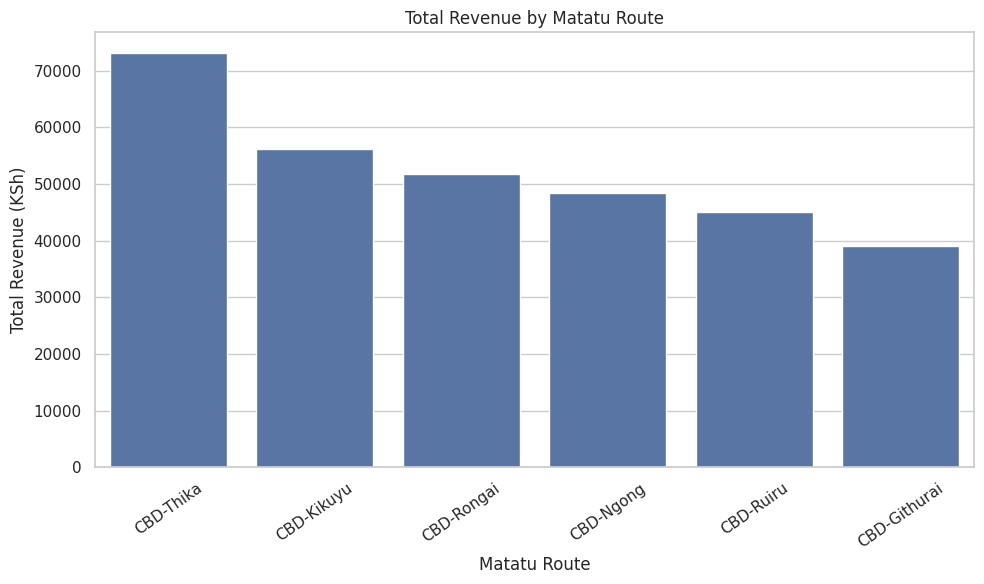

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=revenue_analysis,
    x="route",
    y="total_revenue"
)

plt.title("Total Revenue by Matatu Route")
plt.xlabel("Matatu Route")
plt.ylabel("Total Revenue (KSh)")
plt.xticks(rotation=35)
plt.tight_layout()

plt.savefig(
    "revenue_by_route.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


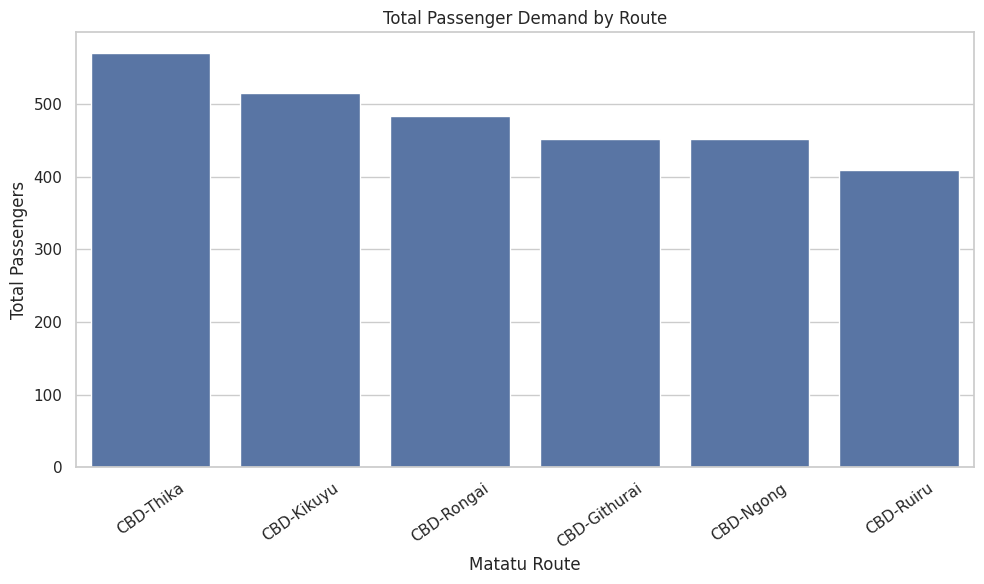

In [20]:

# CHART 2: PASSENGER DEMAND BY ROUTE

plt.figure(figsize=(10, 6))

sns.barplot(
    data=demand_analysis,
    x="route",
    y="total_passengers"
)

plt.title("Total Passenger Demand by Route")
plt.xlabel("Matatu Route")
plt.ylabel("Total Passengers")
plt.xticks(rotation=35)
plt.tight_layout()

plt.savefig(
    "passenger_demand_by_route.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


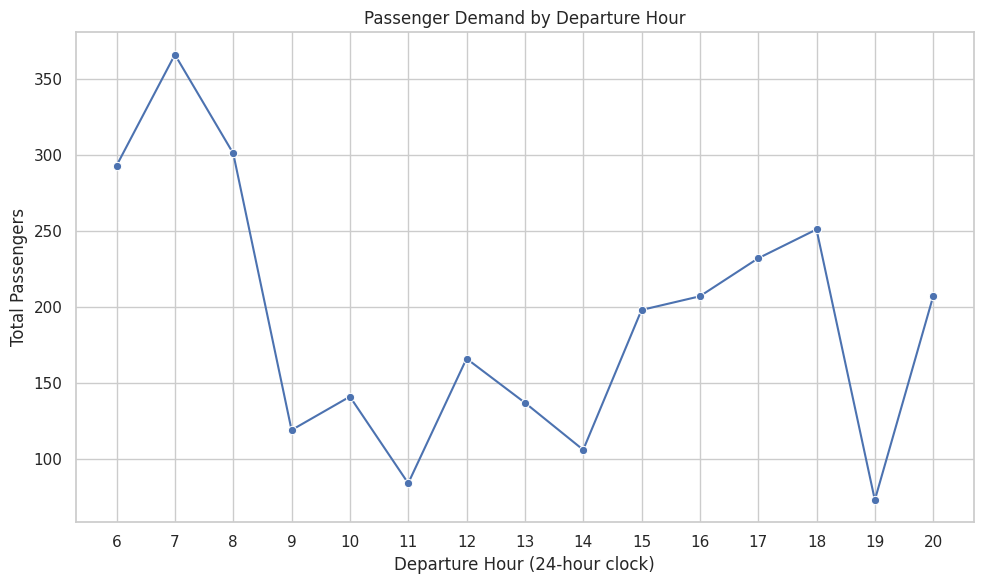

In [21]:

# CHART 3: HOURLY PASSENGER DEMAND

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=hourly_analysis,
    x="departure_hour",
    y="total_passengers",
    marker="o"
)

plt.title("Passenger Demand by Departure Hour")
plt.xlabel("Departure Hour (24-hour clock)")
plt.ylabel("Total Passengers")
plt.xticks(range(6, 21))
plt.tight_layout()

plt.savefig(
    "hourly_passenger_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


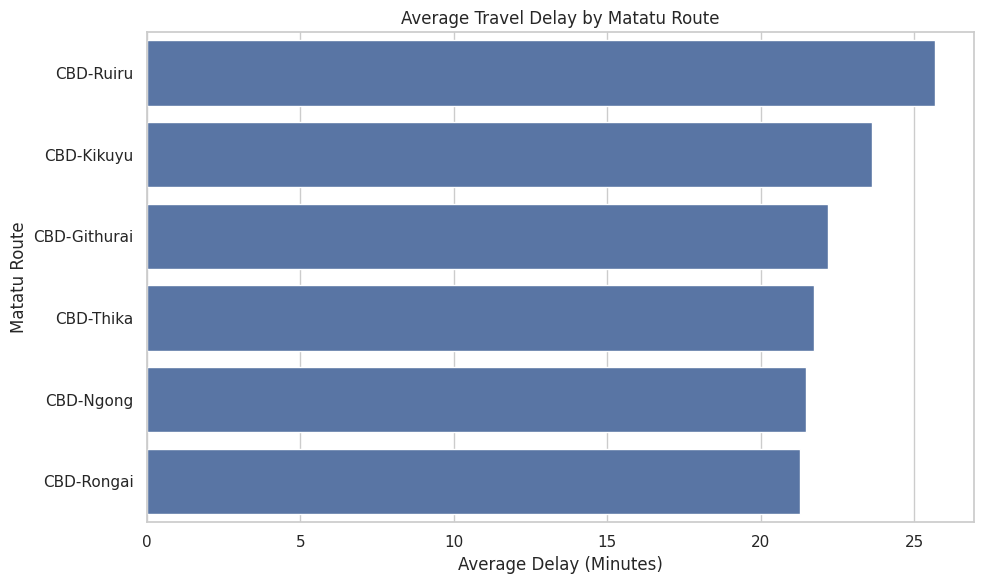

In [22]:

# CHART 4: AVERAGE DELAYS BY ROUTE

plt.figure(figsize=(10, 6))

sns.barplot(
    data=delay_analysis,
    x="average_delay",
    y="route"
)

plt.title("Average Travel Delay by Matatu Route")
plt.xlabel("Average Delay (Minutes)")
plt.ylabel("Matatu Route")
plt.tight_layout()

plt.savefig(
    "average_delay_by_route.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [23]:

# EXPORT ANALYSIS REPORTS

revenue_analysis.to_csv(
    "revenue_analysis.csv", index=False
)

demand_analysis.to_csv(
    "passenger_demand_analysis.csv", index=False
)

hourly_analysis.to_csv(
    "hourly_demand_analysis.csv", index=False
)

delay_analysis.to_csv(
    "delay_analysis.csv", index=False
)

efficiency_analysis.to_csv(
    "route_efficiency_analysis.csv", index=False
)

print("All five analytical reports exported successfully!")


All five analytical reports exported successfully!


In [24]:
import os

folders = [
    "matatu-route-efficiency-analyzer/data",
    "matatu-route-efficiency-analyzer/reports",
    "matatu-route-efficiency-analyzer/images",
    "matatu-route-efficiency-analyzer/notebooks"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [25]:
import os
import shutil

base = "matatu-route-efficiency-analyzer"

# 1. Save the original dataset
df.to_csv(f"{base}/data/matatu_trips.csv", index=False)

# 2. Move analysis reports
report_files = [
    "revenue_analysis.csv",
    "passenger_demand_analysis.csv",
    "hourly_demand_analysis.csv",
    "delay_analysis.csv",
    "route_efficiency_analysis.csv"
]

for file in report_files:
    if os.path.exists(file):
        shutil.move(file, f"{base}/reports/{file}")
    else:
        print("Report not found:", file)

# 3. Move visualization images
image_files = [
    "revenue_by_route.png",
    "passenger_demand_by_route.png",
    "hourly_passenger_demand.png",
    "average_delay_by_route.png"
]

for file in image_files:
    if os.path.exists(file):
        shutil.move(file, f"{base}/images/{file}")
    else:
        print("Image not found:", file)

print("\nPROJECT FILES ORGANIZED!")


PROJECT FILES ORGANIZED!


In [26]:
for folder, subfolders, files in os.walk(base):
    print("\n" + folder)
    for file in files:
        print("  -", file)


matatu-route-efficiency-analyzer

matatu-route-efficiency-analyzer/data
  - matatu_trips.csv

matatu-route-efficiency-analyzer/reports
  - revenue_analysis.csv
  - route_efficiency_analysis.csv
  - hourly_demand_analysis.csv
  - passenger_demand_analysis.csv
  - delay_analysis.csv

matatu-route-efficiency-analyzer/notebooks

matatu-route-efficiency-analyzer/images
  - average_delay_by_route.png
  - hourly_passenger_demand.png
  - passenger_demand_by_route.png
  - revenue_by_route.png


average_delay_by_route.png


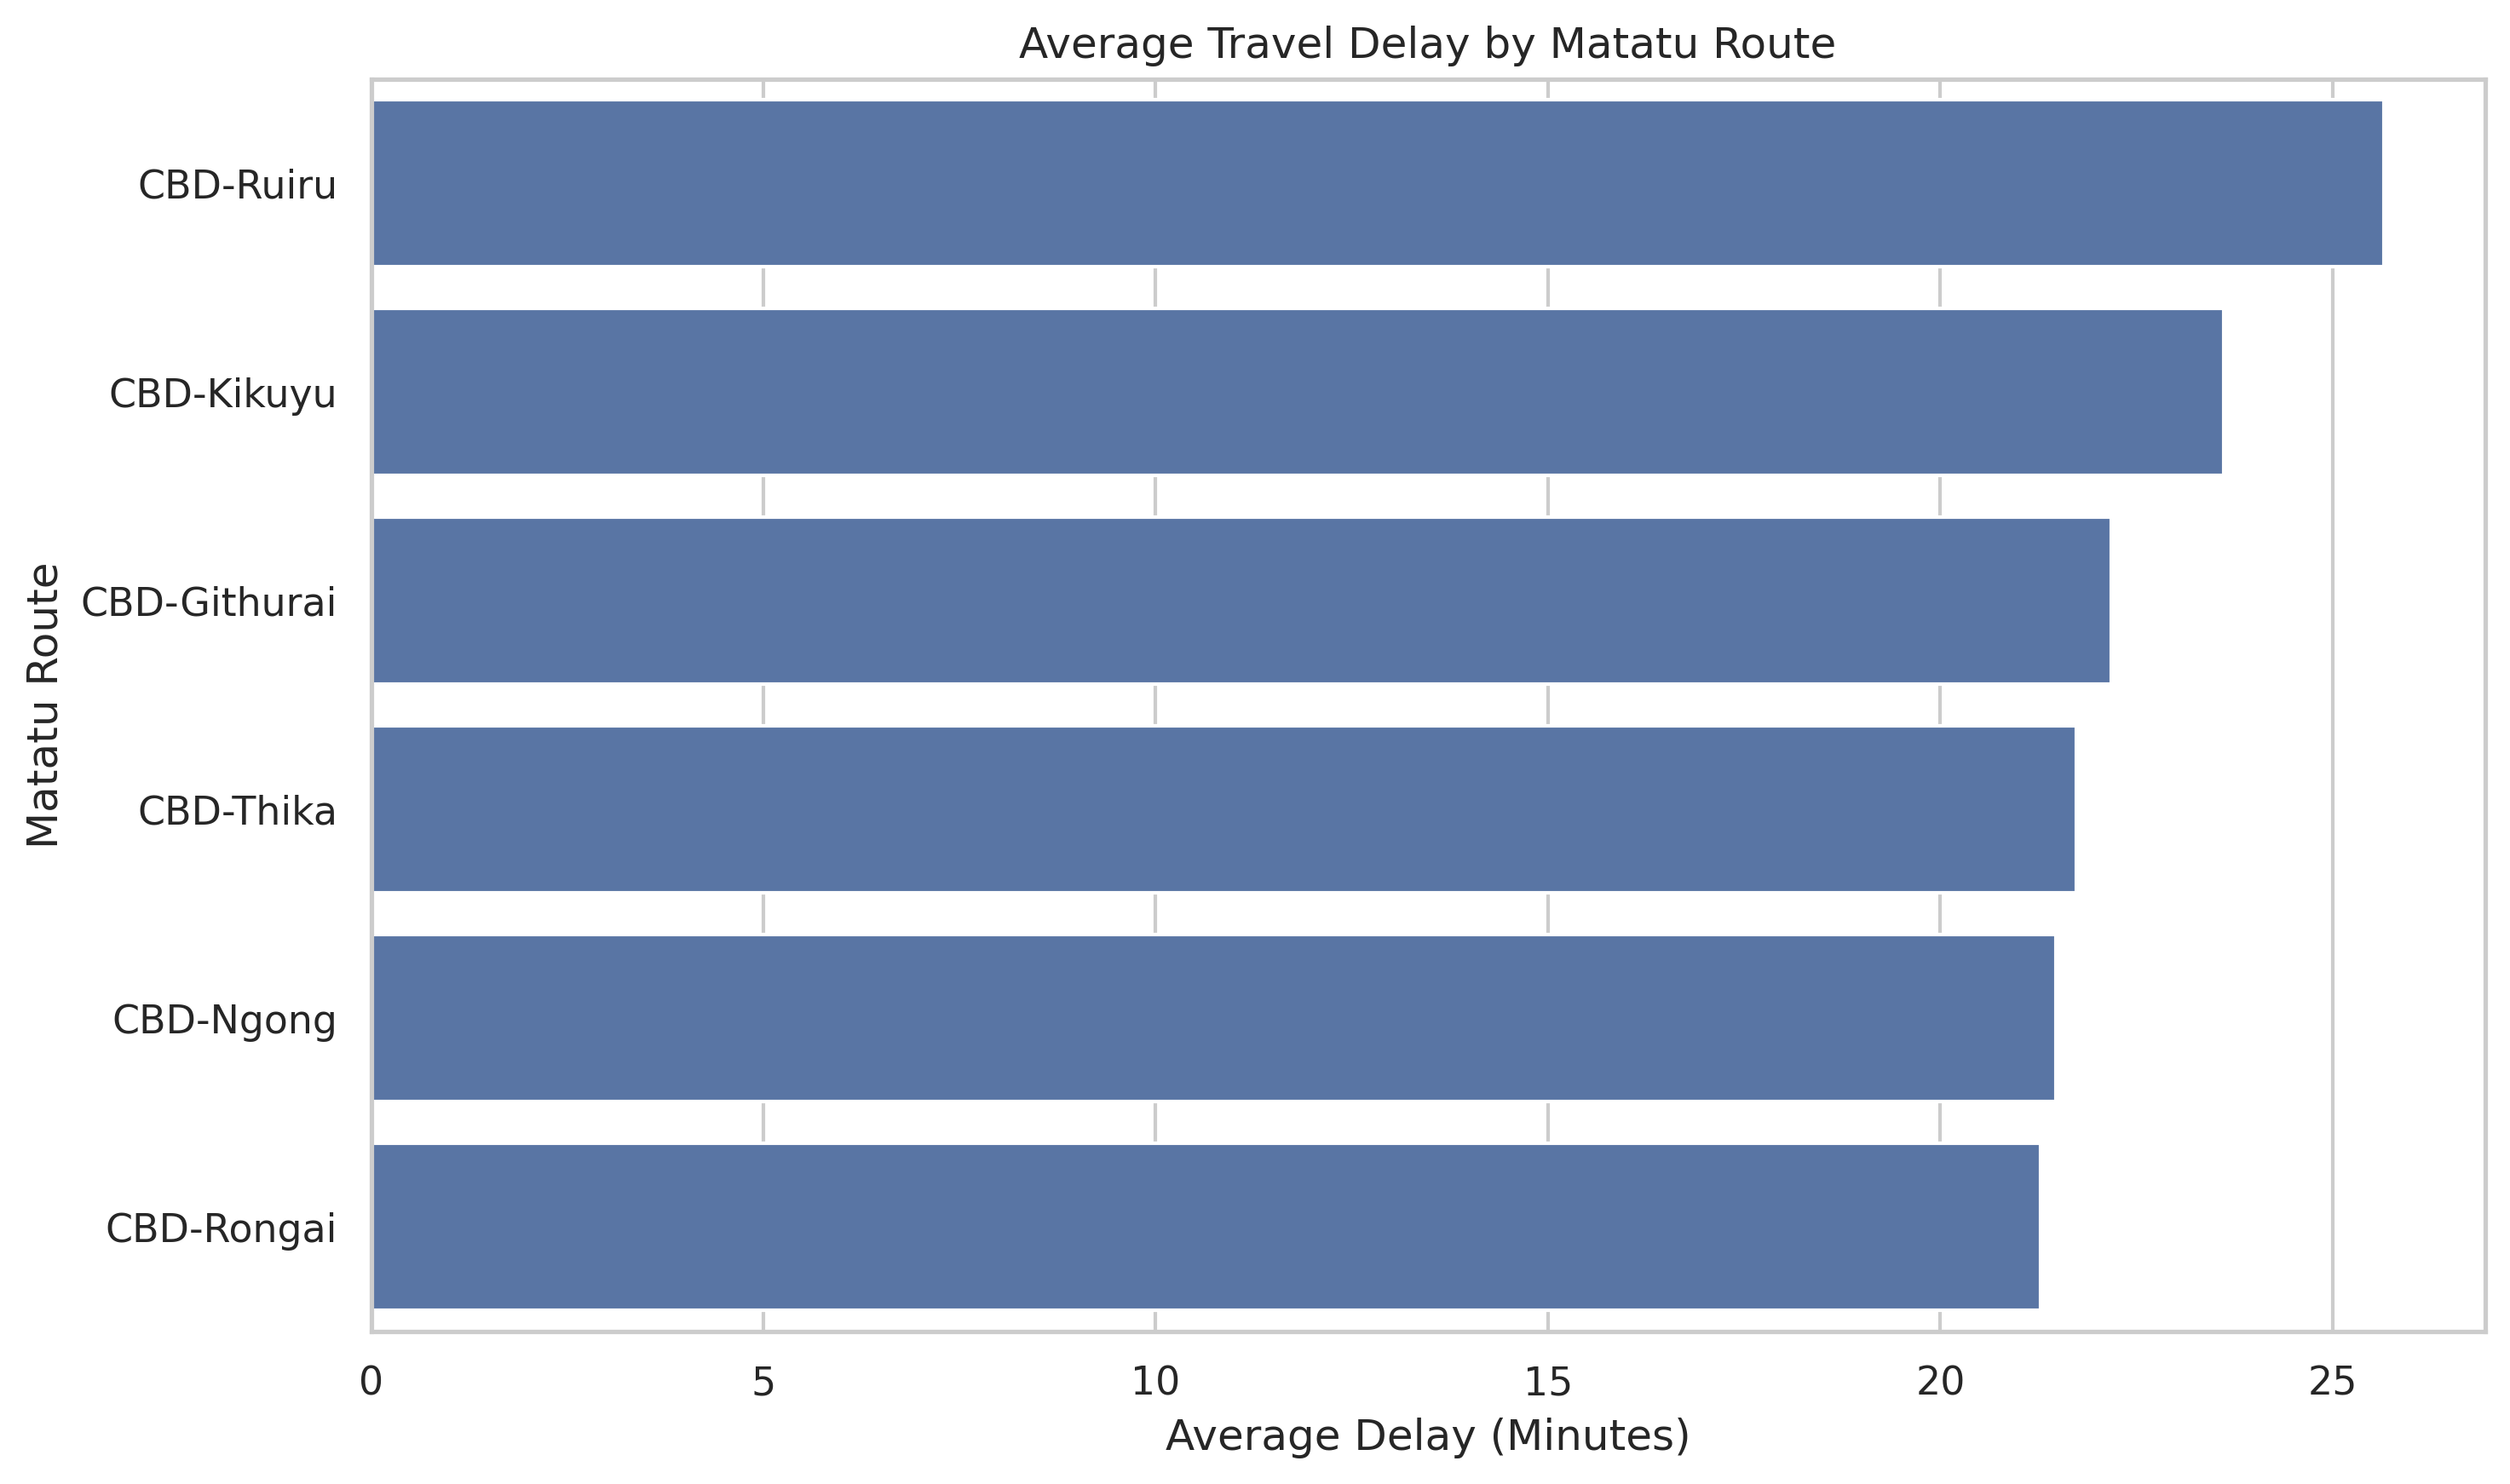

hourly_passenger_demand.png


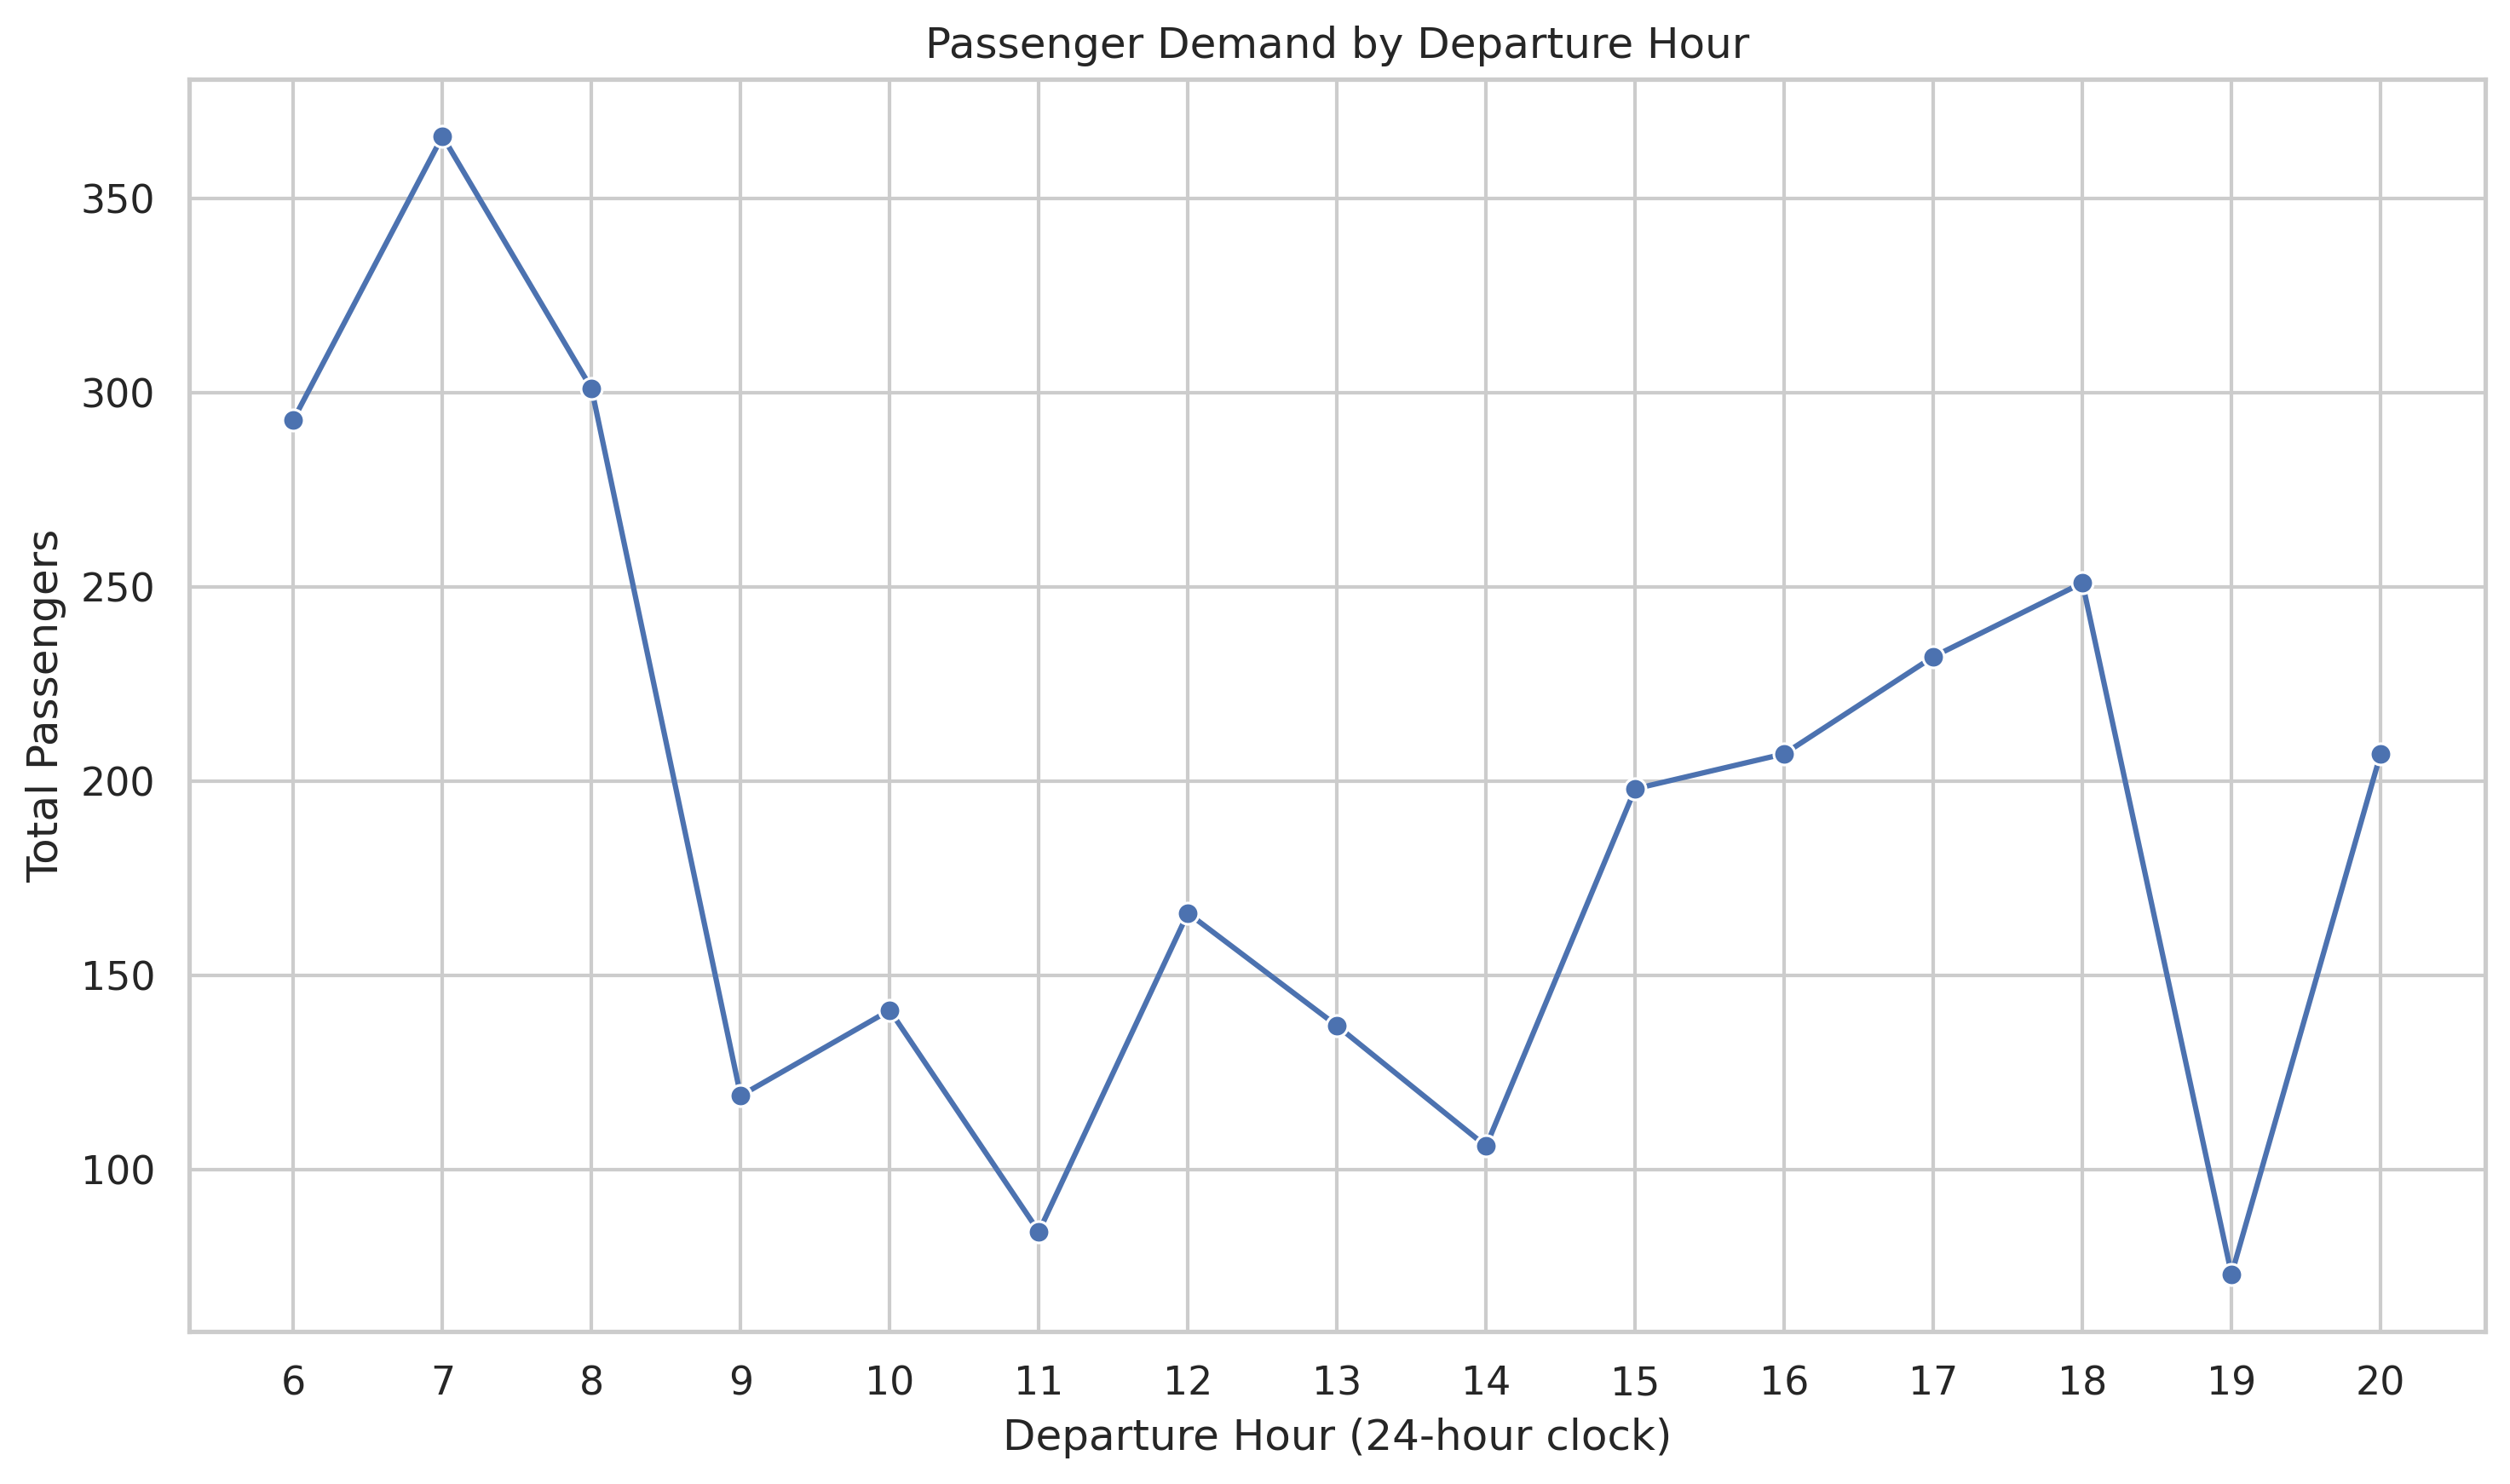

passenger_demand_by_route.png


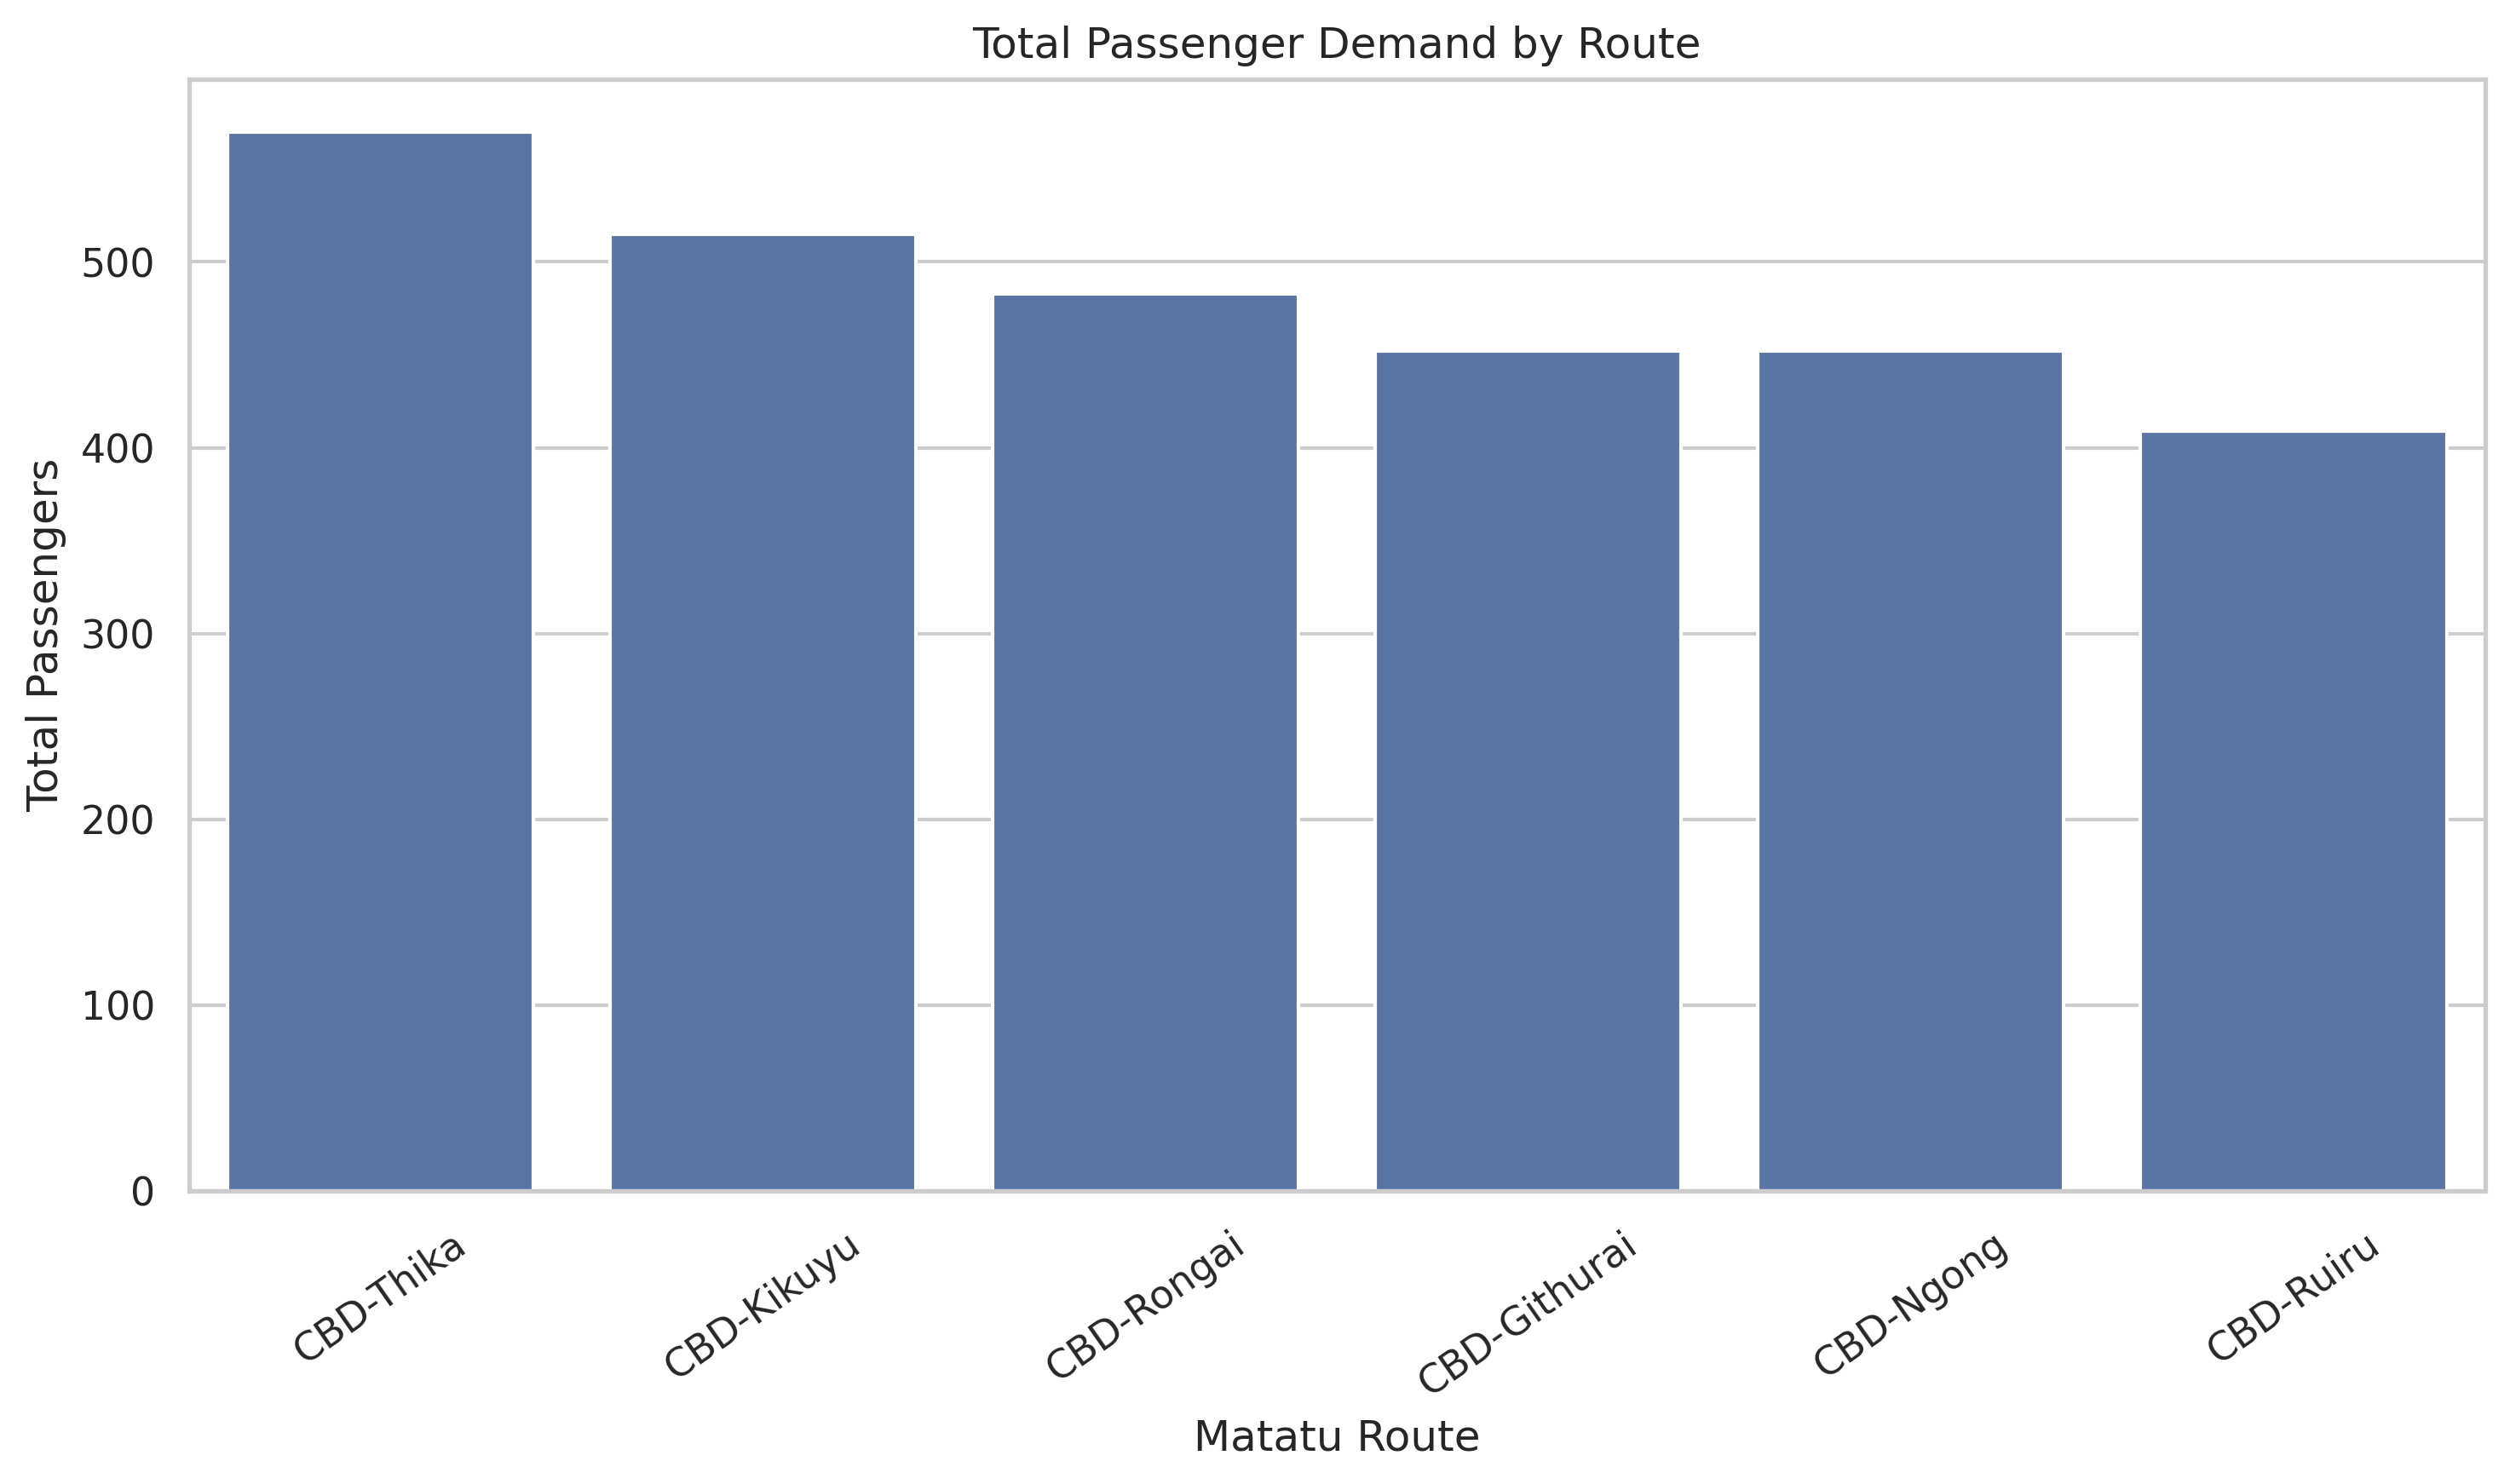

revenue_by_route.png


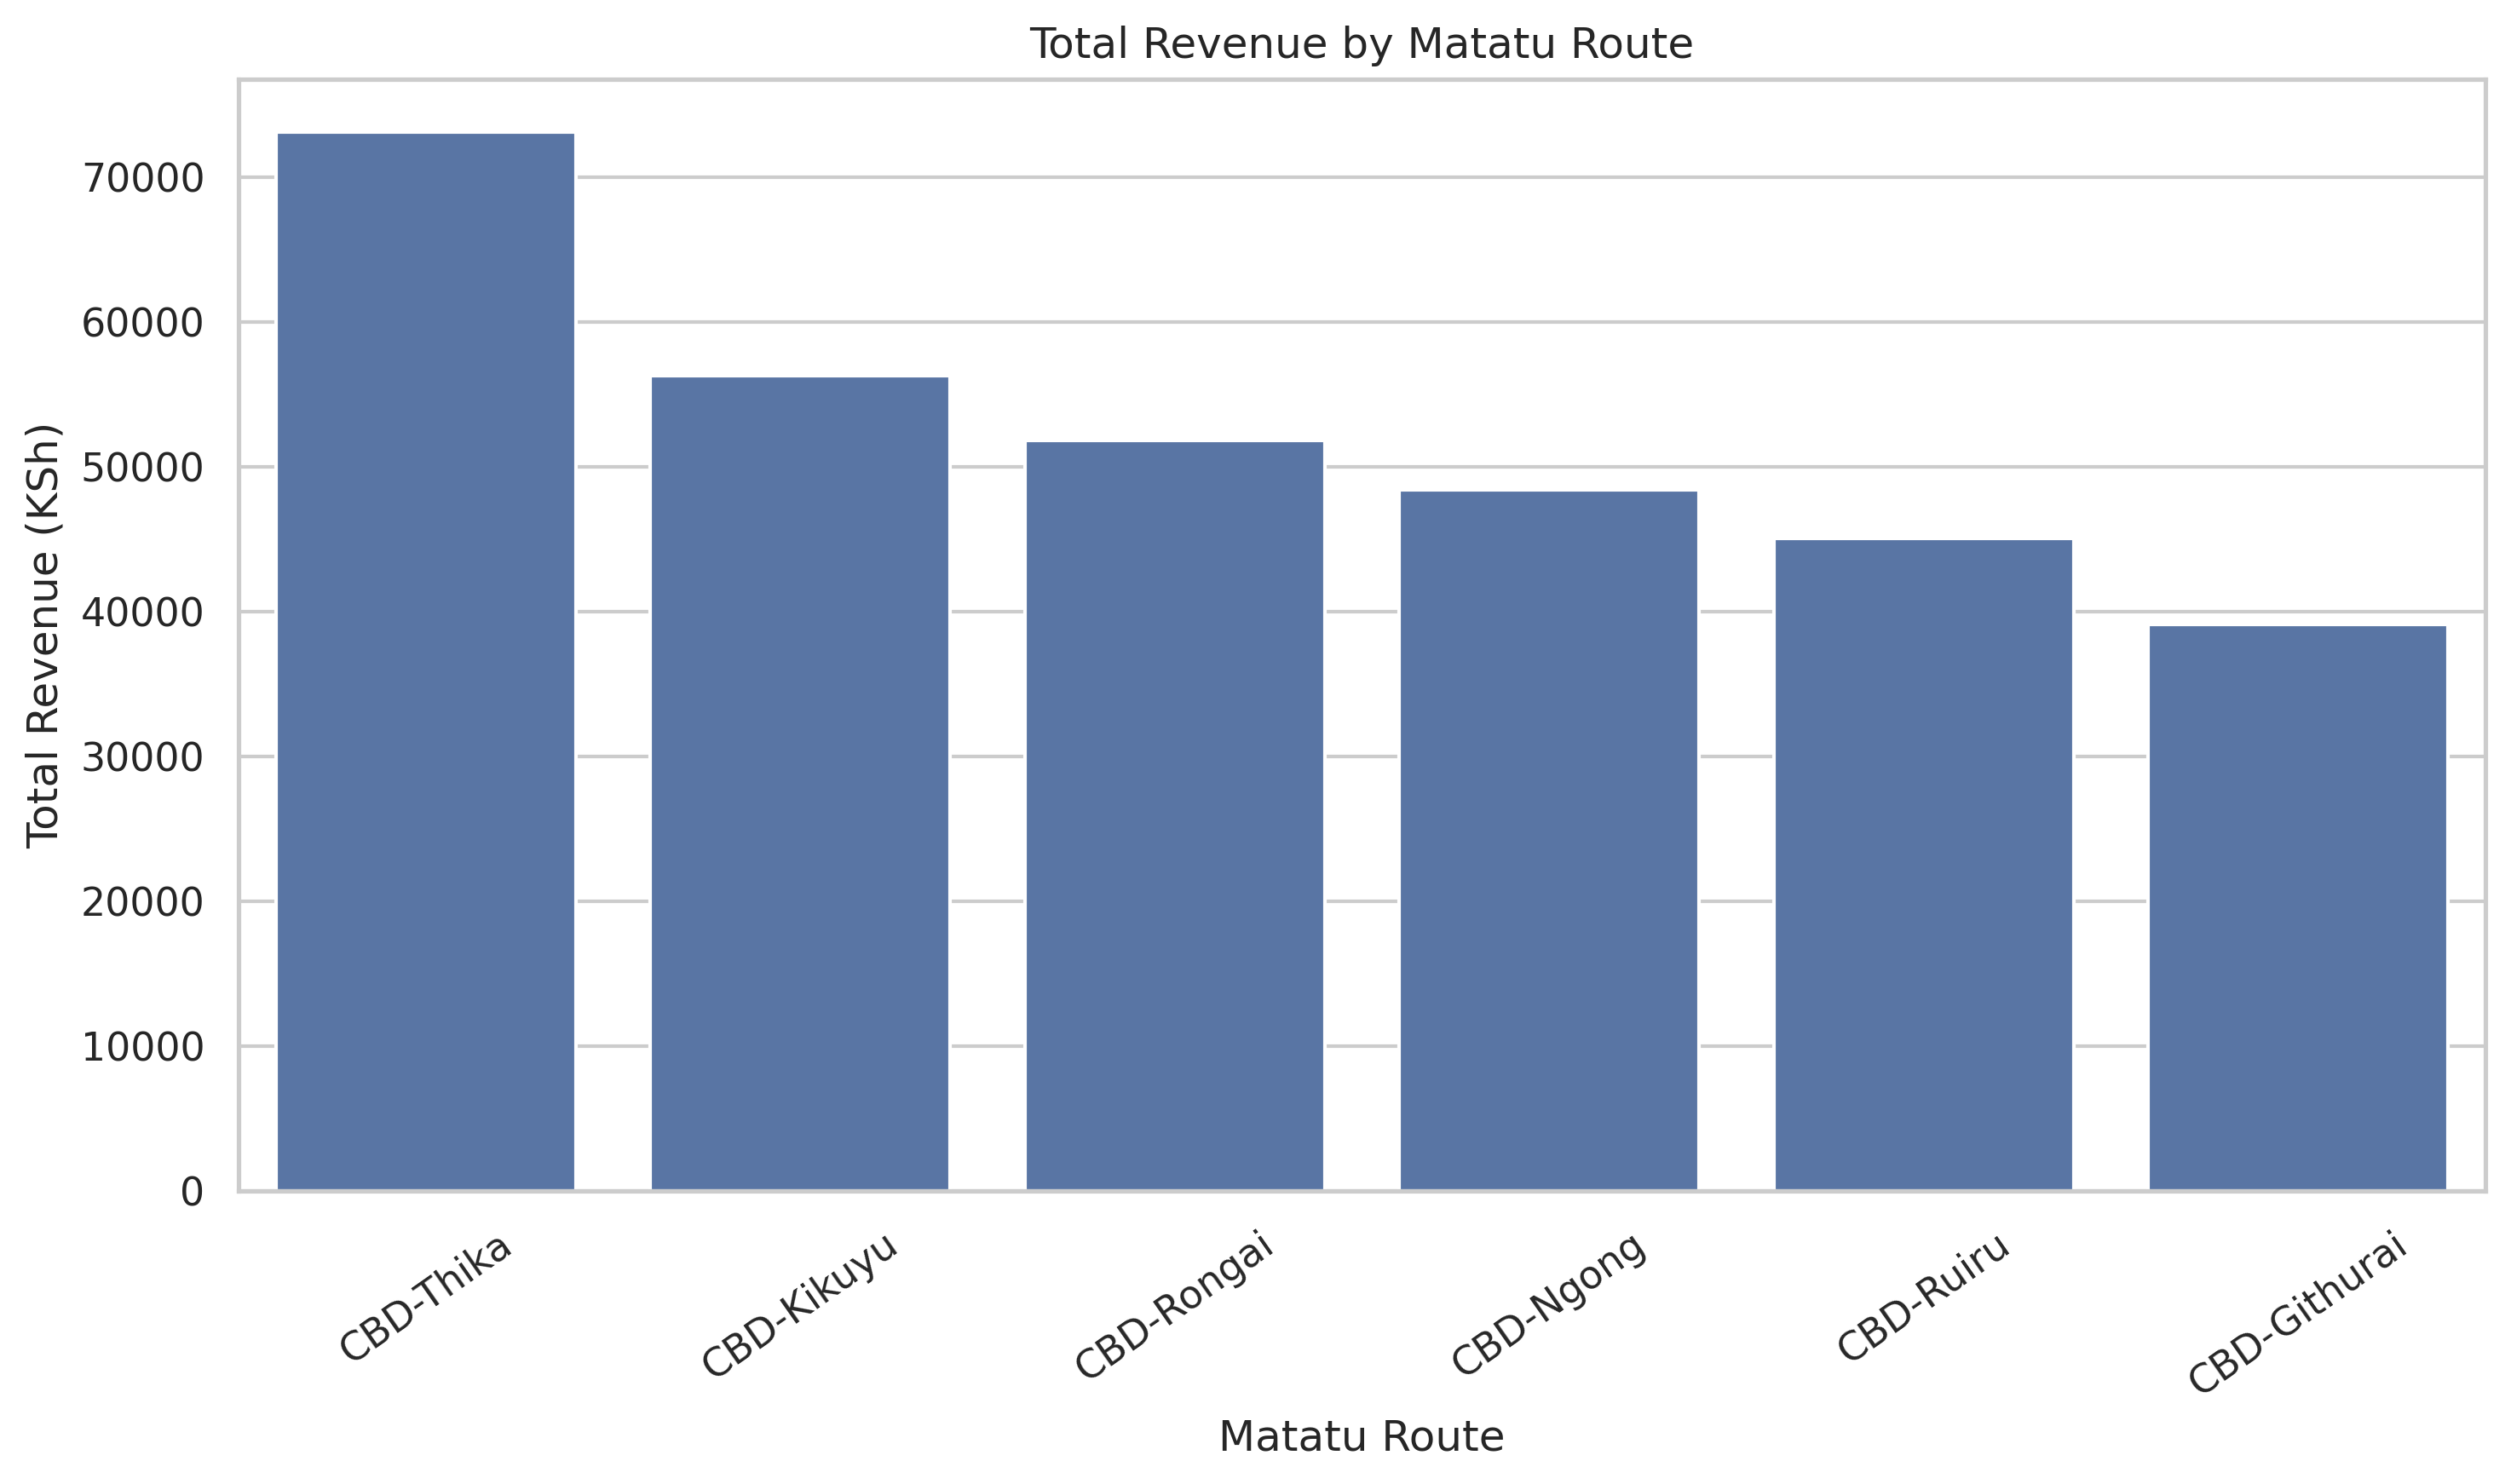

In [27]:
from IPython.display import display, Image
import os

image_folder = "matatu-route-efficiency-analyzer/images"

for filename in os.listdir(image_folder):
    print(filename)
    display(Image(filename=os.path.join(image_folder, filename)))